In [2]:
import yaml
import warnings
import sys

import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm

# make figures paper quality
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
matplotlib.rcParams['font.family'] = 'sans-serif'
matplotlib.rcParams['font.sans-serif'] = 'Arial'

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
# from utils import ...

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']

In [3]:
# counts
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# essential genes
essential = pd.read_csv("../resources/bagel_supplement/CEGv2.txt", sep='\t', index_col=0)
non_essential = pd.read_csv("../resources/bagel_supplement/NEGv1.txt", sep='\t', index_col=0)

# Cell line differences

In [4]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

# Remove initial time points
df = df.loc[:, ~df.columns.str.contains('TP1|TP2|TP3|TP4|TP5')].copy()  

# Define the count matrix (transcripts)
sdf = df.copy()
sdf.index.name = 'sgRNA'
sdf.drop(['Gene', 'ensembl_gene_id', 'transcript_biotype',
    'GuideName', 'GuideSeq', 'MatchPos', 'Guide_Score', 'Region',
    'transcript_length', 'gRNA_occurence', 'transcript_per_gene'], axis=1, inplace=True)
sdf.rename(dict(Transcript_ID='gene'), axis=1, inplace=True)

# Define the count matrix (genes)
sdf = df.copy()
sdf.index.name = 'sgRNA'
sdf.drop(['Transcript_ID', 'ensembl_gene_id', 'transcript_biotype',
    'GuideName', 'GuideSeq', 'MatchPos', 'Guide_Score', 'Region',
    'transcript_length', 'gRNA_occurence', 'transcript_per_gene'], axis=1, inplace=True)
sdf.rename(dict(Gene='gene'), axis=1, inplace=True)
sdf.to_csv('mageck_test_counts.csv')
sdf.head()

,gene,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP6,sym-01-02-TP6,sym-01-03-TP6,sym-02-01-TP6,sym-02-02-TP6,sym-02-03-TP6,sym-03-01-TP6,sym-03-02-TP6,sym-03-03-TP6
sgRNA,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,AATBC,2361,2599,3522,2405,3290,2351,2003,1332,1282,1439,1494,1391
AATBC_ENST00000400385_1562,AATBC,3330,3607,4864,3562,4228,4218,2428,2337,1967,2171,2318,2168
AATBC_ENST00000400385_1938,AATBC,2138,2139,3108,3012,2869,2930,1756,1387,1063,1307,1473,1391
AATBC_ENST00000400385_2713,AATBC,1994,2038,2838,2514,2026,1604,1261,1032,842,1082,1026,1073
AATBC_ENST00000400385_28,AATBC,3321,3027,4610,4197,3811,4010,2416,1735,1300,1813,1975,1842


In [5]:
design_mat = pd.DataFrame(0, index=sdf.columns[1:], columns = ['baseline', 'H1975', 'H1299', 'A549'])
design_mat['baseline'] = 1
for i, line in cell_line_dict.items():
   design_mat[line] = (design_mat.index.str.split('-').str[1] == f'0{i}').astype(int)
design_mat.index.name ='Samples'
design_mat.to_csv('mageck_test_designmat.txt', sep='\t')
design_mat

,baseline,H1975,H1299,A549
Samples,,,,
Sym-pool-1-1,1,0,0,0
Sym-pool-1-2,1,0,0,0
Sym-pool-1-3,1,0,0,0
sym-01-01-TP6,1,1,0,0
sym-01-02-TP6,1,1,0,0
sym-01-03-TP6,1,1,0,0
sym-02-01-TP6,1,0,1,0
sym-02-02-TP6,1,0,1,0
sym-02-03-TP6,1,0,1,0


In [7]:
!mageck mle -k mageck_test_counts.csv -d mageck_test_designmat.txt -n mle_test

In [13]:
tab = pd.read_csv('mle_test.gene_summary.txt', sep='\t', index_col=0)
tab = tab.drop('sgRNA', axis=1)
tab.columns = pd.MultiIndex.from_tuples([tuple(x.split('|')) for x in tab.columns], names=['cell_line', 'variable'])

In [14]:
tab

cell_line     H1975                                                           \
variable       beta        z   p-value       fdr  wald-p-value      wald-fdr   
Gene                                                                           
AATBC      0.069236  1.81120  0.089918  0.283260  7.010800e-02  1.095100e-01   
ACKR2     -0.013451 -0.35737  0.440050  0.629630  7.208100e-01  7.746400e-01   
ACTA2-AS1  0.127820  3.57680  0.016349  0.130430  3.478100e-04  1.110000e-03   
ACTB      -1.665400 -7.20240  0.001362  0.020833  5.916800e-13  9.441200e-12   
ACTG1     -2.049700 -8.67720  0.001362  0.020833  4.056000e-18  1.190900e-16   
...             ...      ...       ...       ...           ...           ...   
ZNF728     0.090244  2.02380  0.113080  0.308550  4.299500e-02  7.425500e-02   
ZNF93     -0.293640 -3.58670  0.919620  0.960170  3.348700e-04  1.078000e-03   
ZNHIT2     0.052904  1.37970  0.219350  0.440220  1.676900e-01  2.326700e-01   
ZRANB2    -0.242320 -3.07470  0.914170  0.958570  2.107400e-03  5.524400e-03   
ZSWIM3     0.045776  1.08450  0.249320  0.474090  2.781500e-01  3.607100e-01   

cell_line     H1299                                                            \
variable       beta         z   p-value       fdr  wald-p-value      wald-fdr   
Gene                                                                            
AATBC      0.193540   5.06270  0.000000  0.000000  4.133200e-07  1.540000e-06   
ACKR2      0.053284   1.41560  0.212530  0.377720  1.568800e-01  1.799200e-01   
ACTA2-AS1  0.152260   4.26030  0.012262  0.063380  2.041700e-05  5.203600e-05   
ACTB      -1.876000  -8.00200  0.001362  0.014925  1.223900e-15  1.321100e-14   
ACTG1     -2.510900 -10.33800  0.000000  0.000000  4.750600e-25  1.162300e-23   
...             ...       ...       ...       ...           ...           ...   
ZNF728     0.098959   2.21910  0.123980  0.257060  2.648200e-02  3.440300e-02   
ZNF93     -0.025549  -0.31205  0.393730  0.585510  7.550000e-01  7.827300e-01   
ZNHIT2     0.133080   3.47060  0.066757  0.175000  5.193100e-04  9.521700e-04   
ZRANB2    -0.499240  -6.32130  0.527250  0.682540  2.593600e-10  1.420700e-09   
ZSWIM3     0.156110   3.69810  0.040872  0.134530  2.172200e-04  4.380300e-04   

cell_line      A549                                                            
variable       beta         z   p-value       fdr  wald-p-value      wald-fdr  
Gene                                                                           
AATBC      0.098062  2.565200  0.004087  0.042254  1.031100e-02  3.064100e-02  
ACKR2     -0.059313 -1.575900  0.516350  0.675580  1.150600e-01  2.264200e-01  
ACTA2-AS1  0.009984  0.279370  0.144410  0.348530  7.799600e-01  8.700500e-01  
ACTB      -1.650400 -7.085700  0.001362  0.023256  1.383400e-12  3.077000e-11  
ACTG1     -1.950700 -8.188900  0.001362  0.023256  2.635300e-16  9.211200e-15  
...             ...       ...       ...       ...           ...           ...  
ZNF728     0.027154  0.608930  0.151230  0.355770  5.425700e-01  6.831000e-01  
ZNF93      0.012271  0.149880  0.207080  0.408600  8.808600e-01  9.276200e-01  
ZNHIT2     0.000568  0.014806  0.265670  0.460990  9.881900e-01  9.922400e-01  
ZRANB2    -0.135720 -1.720800  0.544960  0.709220  8.528000e-02  1.819000e-01  
ZSWIM3     0.019655  0.465630  0.181200  0.387930  6.414800e-01  7.618800e-01  

[734 rows x 18 columns]

In [15]:
stab = tab.loc[:, (slice(None), 'beta')]

In [16]:
stab

cell_line,H1975,H1299,A549
variable,beta,beta,beta
Gene,,,
AATBC,0.069236,0.193540,0.098062
ACKR2,-0.013451,0.053284,-0.059313
ACTA2-AS1,0.127820,0.152260,0.009984
ACTB,-1.665400,-1.876000,-1.650400
ACTG1,-2.049700,-2.510900,-1.950700
...,...,...,...
ZNF728,0.090244,0.098959,0.027154
ZNF93,-0.293640,-0.025549,0.012271


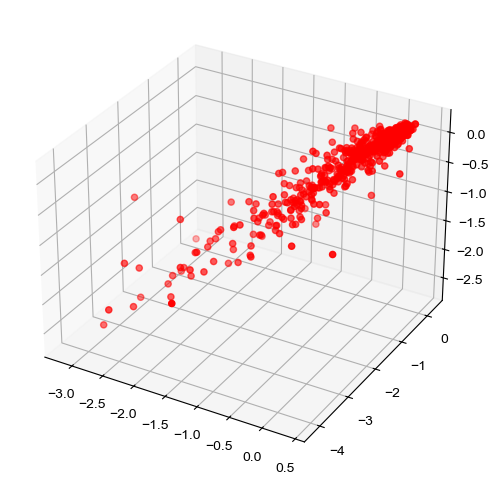

In [17]:
fig, ax = pl.subplots(subplot_kw={'projection': '3d'}, figsize=(8,6))
ax.scatter(stab['H1975'], stab['H1299'], stab['A549'], c='r', marker='o')
pl.show()

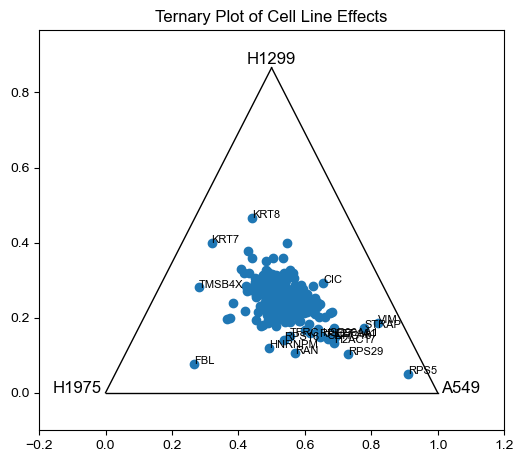

In [74]:
# ternary plot for stab table
Y = -stab.values
# apply softmax
Y = np.exp(Y) / np.sum(np.exp(Y), axis=1)[:, None]
Z = []
for a,b,c in Y:
    x = 0.5 * (2*b+c)/(a+b+c)
    y = np.sqrt(3)/2 * c/(a+b+c)
    Z.append([x,y])
Z = np.array(Z)

# plot ternary plot
fig, ax = pl.subplots(figsize=(6,6*np.sqrt(3)/2), frameon=False)

pl.scatter(Z[:,0], Z[:,1])
mask = np.min(Y, axis=1) < 0.18
for i, txt in enumerate(stab.index):
    if mask[i]:
        ax.annotate(txt, (Z[i,0], Z[i,1]), fontsize=8)
# add triangle axes
pl.plot([0, 0.5], [0, np.sqrt(3)/2], 'k-', lw=1)
pl.plot([0.5, 1], [np.sqrt(3)/2, 0], 'k-', lw=1)
pl.plot([0, 1], [0, 0], 'k-', lw=1)

# add axes labels to the edges of the triangle
pl.text(-0.01, 0, 'H1975', fontsize=12, ha='right')
pl.text(1.01, 0, 'A549', fontsize=12)
pl.text(0.5, np.sqrt(3)/2+0.01, 'H1299', fontsize=12, ha='center')

# increase window size
pl.xlim(-0.2, 1.2)
pl.ylim(-0.1, np.sqrt(3)/2+0.1)

pl.title('Ternary Plot of Cell Line Effects')
pl.show()

In [34]:
tab.index[np.argmax(Z, axis=0)[0]]

'KRT7'

In [43]:
tab.loc['KRT7']

cell_line  variable    
H1975      beta           -1.422300e+00
           z              -7.146200e+00
           p-value         8.174400e-03
           fdr             8.333300e-02
           wald-p-value    8.923500e-13
           wald-fdr        1.364600e-11
H1299      beta            2.001000e-01
           z               1.005900e+00
           p-value         4.087200e-03
           fdr             3.061200e-02
           wald-p-value    3.144700e-01
           wald-fdr        3.439900e-01
A549       beta           -1.444100e+00
           z              -7.243000e+00
           p-value         2.724800e-03
           fdr             3.448300e-02
           wald-p-value    4.389900e-13
           wald-fdr        1.039400e-11
Name: KRT7, dtype: float64

# Timecourse modelling

In [11]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

# Define the count matrix (transcripts)
sdf = df.copy()
sdf.index.name = 'sgRNA'
sdf.drop(['Gene', 'ensembl_gene_id', 'transcript_biotype',
    'GuideName', 'GuideSeq', 'MatchPos', 'Guide_Score', 'Region',
    'transcript_length', 'gRNA_occurence', 'transcript_per_gene'], axis=1, inplace=True)
sdf.rename(dict(Transcript_ID='gene'), axis=1, inplace=True)

# Define the count matrix (genes)
sdf = df.copy()
sdf.index.name = 'sgRNA'
sdf.drop(['Transcript_ID', 'ensembl_gene_id', 'transcript_biotype',
    'GuideName', 'GuideSeq', 'MatchPos', 'Guide_Score', 'Region',
    'transcript_length', 'gRNA_occurence', 'transcript_per_gene'], axis=1, inplace=True)
sdf.rename(dict(Gene='gene'), axis=1, inplace=True)
sdf.to_csv('mageck_test_counts_full.csv')
sdf.head()

,gene,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
sgRNA,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,AATBC,2361,2599,3522,3348,3068,2844,3879,2833,2405,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,AATBC,3330,3607,4864,4715,4947,4048,5521,3671,3562,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,AATBC,2138,2139,3108,3101,3107,2701,3749,2196,3012,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,AATBC,1994,2038,2838,2358,2162,1771,2318,1499,2514,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,AATBC,3321,3027,4610,3655,4296,3384,4973,3267,4197,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842


In [7]:
sdf

,gene,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,...,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP3,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
sgRNA,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,AATBC,2361,2599,3522,3348,3068,2844,3879,2833,2405,...,1494,1747,1655,1494,1545,1298,1388,1842,1277,1391
AATBC_ENST00000400385_1562,AATBC,3330,3607,4864,4715,4947,4048,5521,3671,3562,...,2072,2450,2161,2318,2164,1774,2055,2276,1863,2168
AATBC_ENST00000400385_1938,AATBC,2138,2139,3108,3101,3107,2701,3749,2196,3012,...,1299,1680,1402,1473,1463,1166,1192,1650,1139,1391
AATBC_ENST00000400385_2713,AATBC,1994,2038,2838,2358,2162,1771,2318,1499,2514,...,1175,1268,1071,1026,1157,892,976,1263,835,1073
AATBC_ENST00000400385_28,AATBC,3321,3027,4610,3655,4296,3384,4973,3267,4197,...,1898,2201,1797,1975,2039,1678,1794,2248,1576,1842
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RPS16_ENST00000251453_280,RPS16,2782,2747,3925,2180,457,107,47,0,0,...,337,335,275,171,1198,468,334,230,156,154
RPS16_ENST00000251453_300,RPS16,2046,2117,2834,3516,2088,1163,1157,591,435,...,187,155,153,117,901,319,163,106,88,93
RPS5_ENST00000196551_431,RPS5,2713,2873,3947,3477,2315,1481,1701,921,801,...,865,787,762,652,1532,864,758,669,475,478


In [10]:
design_mat = pd.DataFrame(0, index=sdf.columns[1:], columns = ['baseline', 'H1975', 'H1299', 'A549', 'time'])
design_mat['baseline'] = 1
for i, line in cell_line_dict.items():
   design_mat[line] = (design_mat.index.str.split('-').str[1] == f'0{i}').astype(int)
design_mat['time'] = [int(x[-1]) if 'TP' in x else 0 for x in design_mat.index]
design_mat.index.name ='Samples'
design_mat.to_csv('mageck_test_designmat_full.txt', sep='\t')
design_mat

,baseline,H1975,H1299,A549,time
Samples,,,,,
Sym-pool-1-1,1,0,0,0,0
Sym-pool-1-2,1,0,0,0,0
Sym-pool-1-3,1,0,0,0,0
sym-01-01-TP1,1,1,0,0,1
sym-01-01-TP2,1,1,0,0,2
sym-01-01-TP3,1,1,0,0,3
sym-01-01-TP4,1,1,0,0,4
sym-01-01-TP5,1,1,0,0,5
sym-01-01-TP6,1,1,0,0,6


In [12]:
!mageck mle -k mageck_test_counts_full.csv -d mageck_test_designmat_full.txt -n mle_test_full

INFO  @ Fri, 19 Apr 2024 15:39:43: Parameters: /home/peidli/miniconda3/envs/mageck_env/bin/mageck mle -k mageck_test_counts_full.csv -d mageck_test_designmat_full.txt -n mle_test_full 
INFO  @ Fri, 19 Apr 2024 15:39:45: Cannot parse design matrix as a string; try to parse it as a file name ... 
INFO  @ Fri, 19 Apr 2024 15:39:45: Design matrix: 
INFO  @ Fri, 19 Apr 2024 15:39:45: [[1. 0. 0. 0. 0.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 0. 0. 0. 0.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 0. 0. 0. 0.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 1.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 2.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 3.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 4.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 5.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 6.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 1.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 2.] 
INFO  @ Fri, 19 Apr 2024 15:39:45:  [1. 1. 0. 0. 3.] 
INFO 